# Phase 1 — Cost-Aware and Uncertainty-Quantified Optimisation of Handwriting Protocols for Alzheimer's Disease
### สมุดงานวิเคราะห์สำหรับบทความใหม่ (ต่อยอดจาก IPHA-D-26-00125) — ชุดข้อมูล DARWIN

**ข้ออ้างความใหม่ (novelty claim):** ปฏิบัติต่อการออกแบบ protocol ลายมือเป็นปัญหาการหาค่าเหมาะสมแบบหลายวัตถุประสงค์
(ความสามารถจำแนก × เวลาที่ใช้จริง × ความเสถียร) ภายใต้ repeated nested validation และให้ความไม่แน่นอนระดับบุคคล
ด้วย conformal prediction พร้อมประเมินประโยชน์ทางคลินิกภายใต้ prevalence ของการคัดกรองจริง

| ส่วน | คำถามวิจัย | ผลลัพธ์หลัก (ตาราง / รูป) |
|---|---|---|
| **D** | RQ1 การประเมินแบบไม่ nested ทำให้ผลสูงเกินจริงเท่าใด และแบบจำลองใดดีกว่าจริง | Table D1–D3, Fig. D1–D2 |
| **A** | RQ2 Protocol ใดคุ้มค่าที่สุดเมื่อคิดจาก *เวลาที่ใช้จริง* ไม่ใช่จำนวน task | Table A1–A3, Fig. A1–A3 |
| **E** | RQ3 ระบบให้ความมั่นใจระดับบุคคลที่เชื่อถือได้หรือไม่ และมีประโยชน์ทางคลินิกเพียงใด | Table E1–E4, Fig. E1–E4 |
| **S** | สังเคราะห์ผล | ไฟล์ Excel รวมทุกตาราง + ร่าง Methods/Results ภาษาอังกฤษ (`manuscript_draft.md`) |

**เวลาในการรันบน Colab CPU (โดยประมาณ):** โหมดเต็ม 40–60 นาที, โหมด `FAST = True` 8–12 นาที
ผลการคำนวณแต่ละส่วนถูกบันทึกเป็น cache ใน `outputs/cache/` เมื่อรันซ้ำจะโหลดผลเดิมทันที (ตั้ง `USE_CACHE = False` เพื่อคำนวณใหม่)

> **แนะนำ:** รันครั้งแรกด้วย `FAST = True` เพื่อตรวจว่าทุกเซลล์ทำงาน แล้วจึงรันโหมดเต็ม (`FAST = False`) สำหรับตัวเลขที่จะใช้ในบทความ
> หากต้องการเก็บผลข้ามเซสชัน ให้เชื่อม Google Drive และตั้ง `OUT_DIR` ไปยังโฟลเดอร์ใน Drive

## 0. ติดตั้งไลบรารีและตั้งค่าการทดลอง

In [23]:
!pip install -q xgboost statsmodels openpyxl ucimlrepo

In [24]:
import os, re, glob, zipfile, json, time, warnings, urllib.request, platform
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy import stats
import statsmodels.api as sm

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix, brier_score_loss
from xgboost import XGBClassifier
import sklearn, xgboost

warnings.filterwarnings("ignore")
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30)

# ======================= การตั้งค่าหลัก (CONFIG) =======================
FAST        = False          # True = รันเร็วเพื่อตรวจโค้ด, False = โหมดเต็มสำหรับบทความ
USE_CACHE   = True           # โหลดผลที่คำนวณไว้แล้วจาก outputs/cache
SEED_BASE   = 2026
N_FOLDS, N_INNER = 5, 5      # outer × inner folds

N_REPEATS_D = 3 if FAST else 10   # ส่วน D: repeated nested CV
N_REPEATS_A = 1 if FAST else 5    # ส่วน A: greedy wrapper search (หนักที่สุด)
N_REPEATS_E = 2 if FAST else 5    # ส่วน E: calibration / conformal / DCA
MAX_TASKS   = 8 if FAST else 12   # ขนาด protocol สูงสุดที่ค้นหาในส่วน A
RF_TREES    = 200 if FAST else 400

DELTA_NI    = 0.01           # non-inferiority margin ของ AUROC เทียบ protocol เต็ม
ROPE        = 0.01           # region of practical equivalence สำหรับ Bayesian test
ALPHAS      = [0.05, 0.10, 0.20]       # ระดับ miscoverage ของ conformal prediction
PREVALENCES = [0.05, 0.10, 0.20]       # prevalence สมมติของการคัดกรองจริง
SENS_TARGET = 0.90           # ความไวเป้าหมายสำหรับเลือก threshold แบบคัดกรอง

OUT_DIR   = "outputs"
CACHE_DIR = f"{OUT_DIR}/cache"
os.makedirs(CACHE_DIR, exist_ok=True)

# ค่าคงที่ตามบทความต้นฉบับ (fixed configuration) และ grid สำหรับ nested tuning
FIXED = {"RF": {"k": 100, "leaf": 2},
         "XGB": {"k": 100, "depth": 2, "lr": 0.04},
         "LR": {"k": 50, "C": 0.2}}
GRIDS = {"RF":  [{"k": k, "leaf": l} for k in (50, 100) for l in (1, 2, 5)],
         "XGB": [{"k": k, "depth": d, "lr": lr} for k in (50, 100) for d in (2, 3) for lr in (0.04, 0.10)],
         "LR":  [{"k": k, "C": C} for k in (25, 50, 100) for C in (0.05, 0.2, 1.0)]}
MODEL_LABEL = {"RF": "Random forest", "XGB": "XGBoost", "LR": "Logistic regression"}

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.family": "DejaVu Serif", "font.size": 9.5,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
PALETTE = {"RF": "#1f5f99", "XGB": "#c4572a", "LR": "#6b8e23",
           "Mean-F": "#7f7f7f", "Greedy-AUROC": "#1f5f99", "Greedy-cost": "#c4572a",
           "Full": "#1f5f99", "Reduced": "#c4572a"}

def savefig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(f"{OUT_DIR}/{name}.{ext}", bbox_inches="tight")

def cached(name, fn):
    path = f"{CACHE_DIR}/{name}_{'fast' if FAST else 'full'}.pkl"
    if USE_CACHE and os.path.exists(path):
        print(f"โหลดผลจาก cache: {path}")
        return joblib.load(path)
    t0 = time.time(); res = fn(); joblib.dump(res, path)
    print(f"คำนวณเสร็จใน {(time.time() - t0) / 60:.1f} นาที → บันทึก {path}")
    return res

print(f"Mode: {'FAST' if FAST else 'FULL'} | repeats D/A/E = {N_REPEATS_D}/{N_REPEATS_A}/{N_REPEATS_E} | "
      f"sklearn {sklearn.__version__} | xgboost {xgboost.__version__}")

Mode: FULL | repeats D/A/E = 10/3/5 | sklearn 1.6.1 | xgboost 3.4.1


## 1. โหลดชุดข้อมูล DARWIN และโครงสร้าง task
ชุดข้อมูล: UCI Machine Learning Repository ID 732 — https://archive.ics.uci.edu/dataset/732/darwin
(ไฟล์ zip: https://archive.ics.uci.edu/static/public/732/darwin.zip)

ตัวแปร `total_time{t}` คือระยะเวลาที่ผู้เข้าร่วมใช้ทำ task *t* จึงใช้เป็น **ต้นทุนเวลา (time cost)** ของ task ได้โดยตรง
ในส่วน A ต้นทุนเวลาจะถูกรายงานเป็น *สัดส่วนของเวลาทั้ง protocol* ซึ่งไม่ขึ้นกับหน่วยวัด

> **หมายเหตุ:** `total_time` วัดเฉพาะช่วงเวลาการเขียน (pen activity) ไม่รวมเวลาอธิบายคำสั่ง
> ดังนั้นการลดเวลาที่คำนวณได้เป็นการประมาณเวลาการปฏิบัติงานจริง ไม่ใช่เวลาการประเมินทั้งหมด

In [25]:
#UCI_ZIP_URL = "https://archive.ics.uci.edu/static/public/732/darwin.zip"

def load_darwin():
    for cand in ["DARWIN.csv", "data.csv", "darwin_data/DARWIN.csv", "darwin_data/data.csv"]:
        if os.path.exists(cand):
            print("ใช้ไฟล์ในเครื่อง:", cand); return pd.read_csv(cand)
    try:
        os.makedirs("darwin_data", exist_ok=True)
        urllib.request.urlretrieve(UCI_ZIP_URL, "darwin_data/darwin.zip")
        zipfile.ZipFile("darwin_data/darwin.zip").extractall("darwin_data")
        csv = glob.glob("darwin_data/**/*.csv", recursive=True)[0]
        print("ดาวน์โหลดจาก UCI สำเร็จ:", csv); return pd.read_csv(csv)
    except Exception as e:
        print("ดาวน์โหลด zip ไม่สำเร็จ:", e)
    from ucimlrepo import fetch_ucirepo
    d = fetch_ucirepo(id=732)
    print("ดาวน์โหลดผ่าน ucimlrepo สำเร็จ")
    return pd.concat([d.data.features, d.data.targets], axis=1)

df = load_darwin(); df.columns = [c.strip() for c in df.columns]
df.to_csv("DARWIN.csv", index=False)
label_col = next(c for c in df.columns if c.lower() == "class")
y = df[label_col].astype(str).str.strip().str.upper().map({"P": 1, "H": 0}).astype(int).to_numpy()
X = df.drop(columns=[c for c in df.columns if c.lower() in ("id", "class")]).apply(pd.to_numeric, errors="coerce")
feature_names = X.columns.to_numpy(); X_np = X.to_numpy(float)
N = len(y); PI0 = y.mean()

pat = re.compile(r"^(.*?)(\d+)$")
feature_task = np.array([int(pat.match(c).group(2)) for c in feature_names])
TASKS = np.sort(np.unique(feature_task))
TASK_COLS = {t: np.where(feature_task == t)[0] for t in TASKS}
TT_IDX = {t: int(np.where(feature_names == f"total_time{t}")[0][0]) for t in TASKS}
ALL_COLS = np.arange(X_np.shape[1])

assert X_np.shape == (174, 450) and not np.isnan(X_np).any()
print(f"N = {N} (AD {y.sum()}, HC {N - y.sum()}), p = {X_np.shape[1]}, tasks = {len(TASKS)}")

time_share = pd.Series({t: np.median(X_np[:, TT_IDX[t]]) for t in TASKS})
time_share = time_share / time_share.sum()
print("\nสัดส่วนเวลาของแต่ละ task (median total_time / ผลรวม) — 5 task ที่ใช้เวลามากที่สุด:")
print((time_share.sort_values(ascending=False).head(5) * 100).round(1).astype(str) + " %")

ใช้ไฟล์ในเครื่อง: DARWIN.csv
N = 174 (AD 89, HC 85), p = 450, tasks = 25

สัดส่วนเวลาของแต่ละ task (median total_time / ผลรวม) — 5 task ที่ใช้เวลามากที่สุด:
25    16.5 %
19    14.3 %
24    10.6 %
21     9.0 %
17     7.2 %
dtype: object


## 2. ฟังก์ชันพื้นฐานที่ใช้ร่วมกัน

In [26]:
EPS = 1e-4
def logit(p): p = np.clip(p, EPS, 1 - EPS); return np.log(p / (1 - p))
def expit(z): return 1 / (1 + np.exp(-z))

def make_model(name, params, n_feat, seed):
    sel = ("select", SelectKBest(f_classif, k=min(params.get("k", 100), n_feat)))
    if name == "RF":
        clf = RandomForestClassifier(n_estimators=RF_TREES, min_samples_leaf=params["leaf"], max_features="sqrt",
                                     class_weight="balanced", random_state=seed, n_jobs=-1)
        return Pipeline([sel, ("clf", clf)])
    if name == "XGB":
        clf = XGBClassifier(n_estimators=180, max_depth=params["depth"], learning_rate=params["lr"], subsample=0.8,
                            colsample_bytree=0.7, reg_lambda=2, eval_metric="logloss", random_state=seed,
                            n_jobs=-1, verbosity=0)
        return Pipeline([sel, ("clf", clf)])
    clf = LogisticRegression(C=params["C"], class_weight="balanced", max_iter=3000, random_state=seed)
    return Pipeline([("scale", StandardScaler()), sel, ("clf", clf)])

def fit_predict(name, params, Xtr, ytr, Xte, seed):
    return make_model(name, params, Xtr.shape[1], seed).fit(Xtr, ytr).predict_proba(Xte)[:, 1]

def inner_oof(name, params, Xtr, ytr, inner, seed):
    oof = np.zeros(len(ytr))
    for a, b in inner:
        oof[b] = fit_predict(name, params, Xtr[a], ytr[a], Xtr[b], seed)
    return oof

def outer_splits(seed):  return list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=seed).split(X_np, y))
def inner_splits(ytr, seed): return list(StratifiedKFold(N_INNER, shuffle=True, random_state=seed).split(ytr, ytr))

def binary_metrics(y_true, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, yhat, labels=[0, 1]).ravel()
    return {"AUROC": roc_auc_score(y_true, p), "Accuracy": (tp + tn) / len(y_true),
            "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp), "Brier": brier_score_loss(y_true, p)}

def mean_sd(s, d=3): return f"{np.mean(s):.{d}f} ± {np.std(s, ddof=1) if len(s) > 1 else 0:.{d}f}"

def task_scores(Xtr, ytr):   # คะแนน task แบบบทความต้นฉบับ: ค่าเฉลี่ย ANOVA-F ของ 18 features
    F = np.nan_to_num(f_classif(Xtr, ytr)[0], nan=0.0, posinf=0.0)
    return pd.Series({t: F[TASK_COLS[t]].mean() for t in TASKS})

def cols_of(tasks): return np.sort(np.concatenate([TASK_COLS[t] for t in tasks]))

---
# ส่วน D — Repeated nested cross-validation และการแยกองค์ประกอบของ optimism (RQ1)

**การออกแบบ:** repeated (R ครั้ง) stratified 5-fold outer CV และในแต่ละ outer training fold มี inner 5-fold CV สำหรับเลือก hyperparameter
การเลือก feature (ANOVA-F) อยู่ภายในทุก pipeline

| Variant | ความหมาย |
|---|---|
| **Fixed** | hyperparameter คงที่ตามบทความต้นฉบับ (ไม่มีการ tune) |
| **Nested** | เลือก configuration จาก grid ด้วย inner CV แล้วประเมินบน outer fold ที่ไม่ถูกแตะต้อง — *ค่าประมาณที่ไม่มีอคติ* |
| **Best-of-grid** | ประเมินทุก configuration บน outer CV แล้วรายงานค่าที่ดีที่สุด — *จำลองการ tune บนข้อมูลที่ใช้รายงานผล* |

**องค์ประกอบของ optimism**
- *Tuning optimism* = AUROC(best-of-grid) − AUROC(nested)
- *Selection optimism* = AUROC(เลือก 10 tasks จากข้อมูลทั้งหมด) − AUROC(เลือก 10 tasks ภายใน training fold)

**การเปรียบเทียบแบบจำลอง:** ใช้ **Bayesian correlated t-test** (Corani & Benavoli, 2015) บนผลต่าง AUROC ราย fold
ซึ่งปรับแก้สหสัมพันธ์ระหว่าง fold ที่เกิดจากการใช้ข้อมูลซ้ำ ด้วย $\rho = n_{test}/n = 1/K$

$$\mu \mid \mathbf{d} \sim t_{n-1}\!\left(\bar d,\ \Big(\tfrac{1}{n}+\tfrac{\rho}{1-\rho}\Big)\hat\sigma^2\right)$$

แล้วรายงาน $P(\mu > \text{ROPE})$, $P(|\mu| \le \text{ROPE})$ และ $P(\mu < -\text{ROPE})$ โดย ROPE = 0.01 AUROC
พร้อม Nadeau–Bengio corrected resampled *t*-test เป็นสถิติเชิงความถี่ประกอบ

In [27]:
def run_D():
    pooled, folds, sel_rows, chosen_cfg = [], [], [], []
    naive_tasks = task_scores(X_np, y).sort_values(ascending=False).index[:10].to_numpy()  # ใช้ label ทั้งหมด
    for r in range(N_REPEATS_D):
        seed = SEED_BASE + r
        splits = outer_splits(seed)
        for m in ("RF", "XGB", "LR"):
            grid = GRIDS[m]
            p_fixed = np.zeros(N); p_nested = np.zeros(N); p_grid = np.zeros((len(grid), N))
            for f, (tr, te) in enumerate(splits):
                Xtr, ytr, Xte = X_np[tr], y[tr], X_np[te]
                inner = inner_splits(ytr, seed + 100 + f)
                p_fixed[te] = fit_predict(m, FIXED[m], Xtr, ytr, Xte, seed)
                inner_auc = []
                for g, prm in enumerate(grid):
                    inner_auc.append(roc_auc_score(ytr, inner_oof(m, prm, Xtr, ytr, inner, seed)))
                    p_grid[g, te] = fit_predict(m, prm, Xtr, ytr, Xte, seed)
                best = int(np.argmax(inner_auc)); chosen_cfg.append({"repeat": r, "fold": f, "model": m, **grid[best]})
                p_nested[te] = p_grid[best, te]
                for var, p in (("Fixed", p_fixed), ("Nested", p_nested)):
                    folds.append({"repeat": r, "fold": f, "model": m, "variant": var, "AUROC": roc_auc_score(y[te], p[te])})
            grid_auc = [roc_auc_score(y, p_grid[g]) for g in range(len(grid))]
            for var, p in (("Fixed", p_fixed), ("Nested", p_nested)):
                pooled.append({"repeat": r, "model": m, "variant": var, **binary_metrics(y, p)})
            pooled.append({"repeat": r, "model": m, "variant": "Best-of-grid", "AUROC": max(grid_auc)})
        # selection optimism ของ protocol 10 tasks (RF, fixed)
        p_naive = np.zeros(N); p_fw = np.zeros(N); cn = cols_of(naive_tasks)
        for f, (tr, te) in enumerate(splits):
            p_naive[te] = fit_predict("RF", FIXED["RF"], X_np[tr][:, cn], y[tr], X_np[te][:, cn], seed)
            T = task_scores(X_np[tr], y[tr]).sort_values(ascending=False).index[:10]
            c = cols_of(T); p_fw[te] = fit_predict("RF", FIXED["RF"], X_np[tr][:, c], y[tr], X_np[te][:, c], seed)
        sel_rows.append({"repeat": r, "AUROC naive": roc_auc_score(y, p_naive), "AUROC fold-wise": roc_auc_score(y, p_fw)})
        print(f"  repeat {r + 1}/{N_REPEATS_D} เสร็จ")
    return {"pooled": pd.DataFrame(pooled), "folds": pd.DataFrame(folds),
            "selection": pd.DataFrame(sel_rows), "chosen": pd.DataFrame(chosen_cfg),
            "naive_tasks": sorted(naive_tasks.tolist())}

D = cached("D", run_D)

โหลดผลจาก cache: outputs/cache/D_full.pkl


In [28]:
# ---------- Table D1: ประสิทธิภาพแบบ pooled OOF (mean ± SD ข้าม repeats) ----------
pD = D["pooled"]
rows = []
for m in ("RF", "XGB", "LR"):
    for var in ("Fixed", "Nested"):
        s = pD[(pD.model == m) & (pD.variant == var)]
        rows.append({"Model": MODEL_LABEL[m], "Variant": var,
                     **{k: mean_sd(s[k]) for k in ("AUROC", "Accuracy", "Sensitivity", "Specificity", "Brier")}})
tableD1 = pd.DataFrame(rows)
print(f"Table D1. Repeated ({N_REPEATS_D}×{N_FOLDS}-fold) out-of-fold performance, mean ± SD across repetitions")
display(tableD1)

# ---------- Table D2: การแยกองค์ประกอบ optimism ----------
rows = []
for m in ("RF", "XGB", "LR"):
    a = lambda v: pD[(pD.model == m) & (pD.variant == v)].sort_values("repeat")["AUROC"].to_numpy()
    tun = a("Best-of-grid") - a("Nested"); gain = a("Nested") - a("Fixed")
    rows.append({"Source": "Hyperparameter tuning optimism", "Model": MODEL_LABEL[m],
                 "Definition": "Best-of-grid − Nested", "ΔAUROC": mean_sd(tun, 4),
                 "Positive in": f"{(tun > 0).sum()}/{len(tun)}", "_mean": tun.mean()})
    rows.append({"Source": "Gain from nested tuning", "Model": MODEL_LABEL[m],
                 "Definition": "Nested − Fixed", "ΔAUROC": mean_sd(gain, 4),
                 "Positive in": f"{(gain > 0).sum()}/{len(gain)}", "_mean": gain.mean()})
sel = D["selection"]; so = (sel["AUROC naive"] - sel["AUROC fold-wise"]).to_numpy()
rows.append({"Source": "Task-selection optimism (10 tasks)", "Model": MODEL_LABEL["RF"],
             "Definition": "Full-data − fold-wise selection", "ΔAUROC": mean_sd(so, 4),
             "Positive in": f"{(so > 0).sum()}/{len(so)}", "_mean": so.mean()})
tableD2 = pd.DataFrame(rows)
print("Table D2. Decomposition of optimism in AUROC")
display(tableD2.drop(columns="_mean"))
print("10 tasks ที่เลือกจากข้อมูลทั้งหมด (naive):", D["naive_tasks"])

Table D1. Repeated (10×5-fold) out-of-fold performance, mean ± SD across repetitions


,Model,Variant,AUROC,Accuracy,Sensitivity,Specificity,Brier
0,Random forest,Fixed,0.944 ± 0.005,0.860 ± 0.017,0.867 ± 0.016,0.852 ± 0.030,0.108 ± 0.003
1,Random forest,Nested,0.945 ± 0.006,0.859 ± 0.014,0.867 ± 0.018,0.849 ± 0.028,0.106 ± 0.003
2,XGBoost,Fixed,0.926 ± 0.007,0.839 ± 0.010,0.836 ± 0.022,0.841 ± 0.017,0.112 ± 0.005
3,XGBoost,Nested,0.926 ± 0.008,0.840 ± 0.012,0.840 ± 0.020,0.839 ± 0.024,0.113 ± 0.006
4,Logistic regression,Fixed,0.909 ± 0.011,0.842 ± 0.014,0.816 ± 0.030,0.869 ± 0.019,0.120 ± 0.008
5,Logistic regression,Nested,0.902 ± 0.011,0.834 ± 0.013,0.810 ± 0.019,0.859 ± 0.021,0.124 ± 0.007


Table D2. Decomposition of optimism in AUROC


,Source,Model,Definition,ΔAUROC,Positive in
0,Hyperparameter tuning optimism,Random forest,Best-of-grid − Nested,0.0003 ± 0.0011,6/10
1,Gain from nested tuning,Random forest,Nested − Fixed,0.0015 ± 0.0015,8/10
2,Hyperparameter tuning optimism,XGBoost,Best-of-grid − Nested,0.0056 ± 0.0039,9/10
3,Gain from nested tuning,XGBoost,Nested − Fixed,-0.0005 ± 0.0043,5/10
4,Hyperparameter tuning optimism,Logistic regression,Best-of-grid − Nested,0.0113 ± 0.0077,9/10
5,Gain from nested tuning,Logistic regression,Nested − Fixed,-0.0071 ± 0.0079,2/10
6,Task-selection optimism (10 tasks),Random forest,Full-data − fold-wise selection,0.0080 ± 0.0050,10/10


10 tasks ที่เลือกจากข้อมูลทั้งหมด (naive): [2, 3, 6, 7, 8, 9, 15, 17, 23, 25]


In [29]:
# ---------- Table D3: Bayesian correlated t-test + Nadeau–Bengio corrected t-test ----------
def bayes_corr_ttest(d, rho=1 / N_FOLDS, rope=ROPE):
    n = len(d); mu = d.mean(); var = d.var(ddof=1)
    scale = np.sqrt((1 / n + rho / (1 - rho)) * max(var, 1e-12))
    post = stats.t(df=n - 1, loc=mu, scale=scale)
    pl, pr = post.cdf(-rope), 1 - post.cdf(rope)
    t_nb = mu / scale; p_nb = 2 * stats.t.sf(abs(t_nb), n - 1)
    return {"mean Δ": mu, "P(A better)": pr, "P(ROPE)": 1 - pl - pr, "P(B better)": pl,
            "NB t": t_nb, "NB p": p_nb, "_post": post}

fD = D["folds"][D["folds"].variant == "Nested"]
piv = fD.pivot_table(index=["repeat", "fold"], columns="model", values="AUROC")
rows, posts = [], {}
for A, B in (("RF", "XGB"), ("RF", "LR"), ("XGB", "LR")):
    res = bayes_corr_ttest((piv[A] - piv[B]).to_numpy())
    posts[(A, B)] = res.pop("_post")
    rows.append({"Model A": MODEL_LABEL[A], "Model B": MODEL_LABEL[B], **res})
tableD3 = pd.DataFrame(rows).round(4)
print(f"Table D3. Bayesian correlated t-test on fold-level AUROC differences (nested models; "
      f"n = {len(piv)} folds, ROPE = ±{ROPE})")
display(tableD3)

Table D3. Bayesian correlated t-test on fold-level AUROC differences (nested models; n = 50 folds, ROPE = ±0.01)


,Model A,Model B,mean Δ,P(A better),P(ROPE),P(B better),NB t,NB p
0,Random forest,XGBoost,0.0176,0.7698,0.2253,0.0049,1.7167,0.0923
1,Random forest,Logistic regression,0.0400,0.9413,0.0534,0.0053,2.1250,0.0387
2,XGBoost,Logistic regression,0.0223,0.7090,0.2146,0.0764,1.0031,0.3207


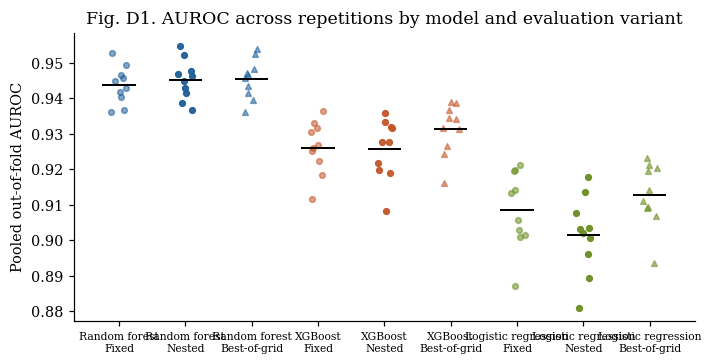

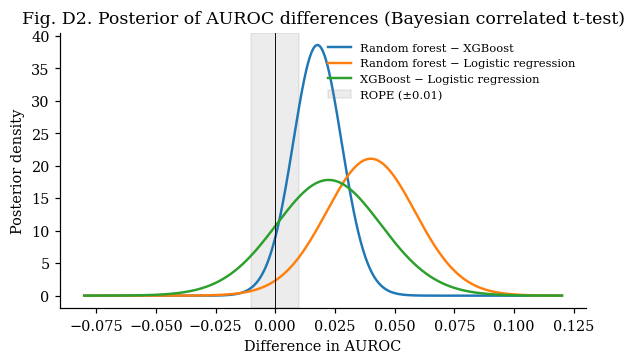

In [30]:
# ---------- Fig. D1: การกระจายของ AUROC ตาม variant / Fig. D2: posterior ของผลต่าง ----------
fig, ax = plt.subplots(figsize=(6.6, 3.4))
order = [(m, v) for m in ("RF", "XGB", "LR") for v in ("Fixed", "Nested", "Best-of-grid")]
for i, (m, v) in enumerate(order):
    vals = pD[(pD.model == m) & (pD.variant == v)]["AUROC"]
    ax.scatter(np.full(len(vals), i) + np.random.default_rng(i).uniform(-.12, .12, len(vals)), vals,
               s=14, color=PALETTE[m], alpha=.55 if v != "Nested" else .95, marker="o" if v != "Best-of-grid" else "^")
    ax.hlines(vals.mean(), i - .25, i + .25, color="black", lw=1.3)
ax.set_xticks(range(len(order)), [f"{MODEL_LABEL[m]}\n{v}" for m, v in order], fontsize=7)
ax.set_ylabel("Pooled out-of-fold AUROC"); ax.set_title("Fig. D1. AUROC across repetitions by model and evaluation variant")
fig.tight_layout(); savefig(fig, "FigD1_AUROC_by_variant"); plt.show()

fig, ax = plt.subplots(figsize=(5.6, 3.4))
xs = np.linspace(-0.08, 0.12, 600)
for (A, B), post in posts.items():
    ax.plot(xs, post.pdf(xs), lw=1.6, label=f"{MODEL_LABEL[A]} − {MODEL_LABEL[B]}")
ax.axvspan(-ROPE, ROPE, color="grey", alpha=.15, label=f"ROPE (±{ROPE})")
ax.axvline(0, color="black", lw=.6)
ax.set(xlabel="Difference in AUROC", ylabel="Posterior density",
       title="Fig. D2. Posterior of AUROC differences (Bayesian correlated t-test)")
ax.legend(fontsize=7.5); fig.tight_layout(); savefig(fig, "FigD2_Bayesian_posterior"); plt.show()

---
# ส่วน A — การเลือก protocol แบบหลายวัตถุประสงค์: AUROC × เวลาที่ใช้จริง (RQ2)

ภายในแต่ละ outer training fold (ไม่ใช้ข้อมูล outer test เลย) สร้างลำดับ protocol ขนาด 1 ถึง `MAX_TASKS` ด้วย 3 กลยุทธ์

| กลยุทธ์ | เกณฑ์การเพิ่ม task |
|---|---|
| **Mean-F** (วิธีของบทความต้นฉบับ) | เรียงตามค่าเฉลี่ย ANOVA-F ของ task — univariate, ไม่คิดความซ้ำซ้อน |
| **Greedy-AUROC** (wrapper) | เพิ่ม task ที่ทำให้ inner-CV AUROC สูงสุด — คำนึงถึงข้อมูลที่ *เพิ่มเติม* จาก task ที่เลือกแล้ว |
| **Greedy-cost** (cost-effective wrapper) | เพิ่ม task ที่ให้ $\Delta\text{AUROC}_{inner} / c_t$ สูงสุด โดย $c_t$ = สัดส่วนเวลาของ task จาก median `total_time` ใน training |

**Surrogate-guided search:** การค้นหาใน inner loop ใช้ L2-logistic regression ซึ่งเร็ว (ทำให้ประเมินผู้สมัครหลายพันชุดได้)
ส่วนการประเมินบน outer fold ใช้ random forest ตาม configuration ของบทความต้นฉบับ

**ต้นทุนเวลาที่เกิดขึ้นจริง:** คำนวณจาก *ผู้เข้าร่วมใน outer test fold* ว่าเวลาของ task ที่เลือกคิดเป็นกี่ % ของเวลาทั้ง 25 tasks

**Protocol ที่แนะนำ:** protocol ที่ใช้เวลาน้อยที่สุดซึ่งยังผ่านเกณฑ์ non-inferiority คือ ค่าเฉลี่ย ΔAUROC เทียบ protocol เต็ม ≥ −δ (δ = 0.01)

In [51]:
def surrogate_auc(Xtr, ytr, tasks, inner):
    c = cols_of(tasks); oof = np.zeros(len(ytr))
    for a, b in inner:
        m = Pipeline([("s", StandardScaler()),
                      ("c", LogisticRegression(C=0.2, class_weight="balanced", max_iter=2000))])
        oof[b] = m.fit(Xtr[a][:, c], ytr[a]).predict_proba(Xtr[b][:, c])[:, 1]
    return roc_auc_score(ytr, oof)

def task_cost(Xtr):
    c = pd.Series({t: max(np.median(Xtr[:, TT_IDX[t]]), 1e-9) for t in TASKS})
    return c / c.sum()

def greedy_path(Xtr, ytr, inner, cost, mode, max_size):
    sel, cur, path, remaining = [], 0.5, [], list(TASKS)
    for _ in range(max_size):
        res = {t: surrogate_auc(Xtr, ytr, sel + [t], inner) for t in remaining}
        if mode == "auc":
            best = max(remaining, key=lambda t: res[t])
        else:
            pos = [t for t in remaining if res[t] > cur]
            best = max(pos, key=lambda t: (res[t] - cur) / cost[t]) if pos else max(remaining, key=lambda t: res[t])
        sel.append(best); remaining.remove(best); cur = res[best]; path.append(list(sel))
    return path

def meanF_path(Xtr, ytr, max_size):
    order = task_scores(Xtr, ytr).sort_values(ascending=False).index.tolist()
    return [order[:m] for m in range(1, max_size + 1)]

def select_path(strategy, Xtr, ytr, inner, max_size):
    if strategy == "Mean-F": return meanF_path(Xtr, ytr, max_size)
    return greedy_path(Xtr, ytr, inner, task_cost(Xtr), "auc" if strategy == "Greedy-AUROC" else "cost", max_size)

def realized_time_frac(Xte, tasks):
    tot = Xte[:, [TT_IDX[t] for t in TASKS]].sum(1)
    return Xte[:, [TT_IDX[t] for t in tasks]].sum(1) / tot

STRATEGIES = ["Mean-F", "Greedy-AUROC", "Greedy-cost"]

In [53]:
def run_A():
    sel_rows, pooled = [], []
    for r in range(N_REPEATS_A):
        seed = SEED_BASE + r
        splits = outer_splits(seed)
        P = {(s, m): np.zeros(N) for s in STRATEGIES for m in range(1, MAX_TASKS + 1)}
        TF = {k: np.zeros(N) for k in P}
        p_full = np.zeros(N)
        for f, (tr, te) in enumerate(splits):
            Xtr, ytr, Xte = X_np[tr], y[tr], X_np[te]
            inner = inner_splits(ytr, seed + 100 + f)
            p_full[te] = fit_predict("RF", FIXED["RF"], Xtr, ytr, Xte, seed)
            for s in STRATEGIES:
                t0 = time.time()
                for m, tasks in enumerate(select_path(s, Xtr, ytr, inner, MAX_TASKS), 1):
                    c = cols_of(tasks)
                    P[(s, m)][te] = fit_predict("RF", FIXED["RF"], Xtr[:, c], ytr, Xte[:, c], seed)
                    TF[(s, m)][te] = realized_time_frac(Xte, tasks)
                    sel_rows.append({"repeat": r, "fold": f, "strategy": s, "m": m, "tasks": tuple(sorted(tasks))})
                print(f"  repeat {r + 1} fold {f + 1} {s:<13s} {time.time() - t0:5.1f} s")
        auc_full = roc_auc_score(y, p_full)
        pooled.append({"repeat": r, "strategy": "Full (25 tasks)", "m": 25, "time_frac": 1.0, **binary_metrics(y, p_full),
                       "ΔAUROC": 0.0})
        for (s, m), p in P.items():
            pooled.append({"repeat": r, "strategy": s, "m": m, "time_frac": TF[(s, m)].mean(),
                           **binary_metrics(y, p), "ΔAUROC": roc_auc_score(y, p) - auc_full})
    return {"pooled": pd.DataFrame(pooled), "selections": pd.DataFrame(sel_rows)}

N_REPEATS_A = 5
print("N_REPEATS_A =", N_REPEATS_A, "| cache dir:", os.path.abspath(CACHE_DIR))
#A = cached("A", run_A)
A = cached(f"A_r{N_REPEATS_A}_m{MAX_TASKS}", run_A)

  repeat 1 fold 1 Mean-F         15.6 s
  repeat 1 fold 1 Greedy-AUROC   26.9 s
  repeat 1 fold 1 Greedy-cost    26.6 s
  repeat 1 fold 2 Mean-F         13.2 s
  repeat 1 fold 2 Greedy-AUROC   27.1 s
  repeat 1 fold 2 Greedy-cost    26.3 s
  repeat 1 fold 3 Mean-F         13.2 s
  repeat 1 fold 3 Greedy-AUROC   26.1 s
  repeat 1 fold 3 Greedy-cost    26.4 s
  repeat 1 fold 4 Mean-F         15.2 s
  repeat 1 fold 4 Greedy-AUROC   26.0 s
  repeat 1 fold 4 Greedy-cost    26.5 s
  repeat 1 fold 5 Mean-F         13.5 s
  repeat 1 fold 5 Greedy-AUROC   26.3 s
  repeat 1 fold 5 Greedy-cost    26.3 s
  repeat 2 fold 1 Mean-F         13.2 s
  repeat 2 fold 1 Greedy-AUROC   25.9 s
  repeat 2 fold 1 Greedy-cost    26.6 s
  repeat 2 fold 2 Mean-F         13.2 s
  repeat 2 fold 2 Greedy-AUROC   25.9 s
  repeat 2 fold 2 Greedy-cost    26.1 s
  repeat 2 fold 3 Mean-F         13.3 s
  repeat 2 fold 3 Greedy-AUROC   25.7 s
  repeat 2 fold 3 Greedy-cost    25.6 s
  repeat 2 fold 4 Mean-F         13.2 s


In [70]:
C = cached(f"C_{REC_STRATEGY}_{REC_M}_B{B_CONS}_r{N_REPEATS_A}", run_C)

  repeat 1 fold 1: [2, 7, 8, 13, 16, 18, 19, 20, 21]


KeyboardInterrupt: 

In [54]:
pA = A["pooled"]
summ = (pA.groupby(["strategy", "m"])
          .agg(AUROC=("AUROC", "mean"), AUROC_sd=("AUROC", "std"), dAUROC=("ΔAUROC", "mean"),
               dAUROC_sd=("ΔAUROC", "std"), time_frac=("time_frac", "mean"),
               Sensitivity=("Sensitivity", "mean"), Specificity=("Specificity", "mean"))
          .reset_index().fillna({"AUROC_sd": 0, "dAUROC_sd": 0}))
full_auc = summ.loc[summ.strategy == "Full (25 tasks)", "AUROC"].item()
cand = summ[summ.strategy != "Full (25 tasks)"].copy()

# Pareto front: ลดเวลา และเพิ่ม AUROC
cand = cand.sort_values(["time_frac", "AUROC"], ascending=[True, False])
best_so_far, pareto = -np.inf, []
for _, row in cand.iterrows():
    pareto.append(row.AUROC > best_so_far); best_so_far = max(best_so_far, row.AUROC)
cand["Pareto"] = pareto

# protocol ที่แนะนำ: เวลาน้อยที่สุดที่ผ่าน non-inferiority
#ni = cand[cand.dAUROC >= -DELTA_NI]
ni = cand[cand.dAUROC - cand.dAUROC_sd >= -DELTA_NI]
REC = (ni.sort_values(["time_frac", "m"]).iloc[0] if len(ni) else cand.sort_values("AUROC", ascending=False).iloc[0])
REC_STRATEGY, REC_M = REC.strategy, int(REC.m)
# protocol ที่ใช้ task น้อยที่สุดที่ผ่านเกณฑ์ (เพื่อเปรียบเทียบกับการนับจำนวน task)
REC_FEWEST = (ni.sort_values(["m", "time_frac"]).iloc[0] if len(ni) else REC)

tableA1 = cand.assign(**{
    "AUROC": cand.apply(lambda r: f"{r.AUROC:.3f} ± {r.AUROC_sd:.3f}", axis=1),
    "ΔAUROC vs full": cand.apply(lambda r: f"{r.dAUROC:+.4f} ± {r.dAUROC_sd:.4f}", axis=1),
    "Time (% of full)": (cand.time_frac * 100).round(1),
    "Time saved (%)": ((1 - cand.time_frac) * 100).round(1),
    "Sens.": cand.Sensitivity.round(3), "Spec.": cand.Specificity.round(3),
    "Non-inferior": cand.dAUROC >= -DELTA_NI})[
    ["strategy", "m", "AUROC", "ΔAUROC vs full", "Time (% of full)", "Time saved (%)", "Sens.", "Spec.", "Non-inferior", "Pareto"]]
tableA1 = tableA1.sort_values(["strategy", "m"]).reset_index(drop=True)
print(f"Full protocol (25 tasks) AUROC = {full_auc:.3f}")
print(f"Table A1. Protocol performance and realised time cost (mean over {N_REPEATS_A} repetition(s) × {N_FOLDS} outer folds)")
display(tableA1)
print(f"\n► Protocol ที่แนะนำ (เวลาน้อยที่สุดที่ non-inferior, δ = {DELTA_NI}): {REC_STRATEGY}, m = {REC_M} tasks, "
      f"time = {REC.time_frac * 100:.1f}% ของ protocol เต็ม, ΔAUROC = {REC.dAUROC:+.4f}")
print(f"► Protocol ที่ใช้ task น้อยที่สุดที่ non-inferior: {REC_FEWEST.strategy}, m = {int(REC_FEWEST.m)}, "
      f"time = {REC_FEWEST.time_frac * 100:.1f}%")

Full protocol (25 tasks) AUROC = 0.946
Table A1. Protocol performance and realised time cost (mean over 3 repetition(s) × 5 outer folds)


,strategy,m,AUROC,ΔAUROC vs full,Time (% of full),Time saved (%),Sens.,Spec.,Non-inferior,Pareto
0,Greedy-AUROC,1,0.800 ± 0.011,-0.1462 ± 0.0119,5.8,94.2,0.704,0.765,False,False
1,Greedy-AUROC,2,0.884 ± 0.003,-0.0616 ± 0.0089,18.1,81.9,0.783,0.847,False,False
2,Greedy-AUROC,3,0.905 ± 0.017,-0.0408 ± 0.0202,23.9,76.1,0.813,0.839,False,False
3,Greedy-AUROC,4,0.931 ± 0.006,-0.0148 ± 0.0114,29.6,70.4,0.831,0.851,False,False
4,Greedy-AUROC,5,0.939 ± 0.004,-0.0074 ± 0.0088,34.5,65.5,0.869,0.863,True,True
5,Greedy-AUROC,6,0.939 ± 0.008,-0.0074 ± 0.0100,38.0,62.0,0.865,0.855,True,False
6,Greedy-AUROC,7,0.939 ± 0.003,-0.0069 ± 0.0060,40.7,59.3,0.861,0.855,True,False
7,Greedy-AUROC,8,0.939 ± 0.007,-0.0071 ± 0.0124,45.1,54.9,0.858,0.859,True,False
8,Greedy-AUROC,9,0.938 ± 0.010,-0.0082 ± 0.0119,48.4,51.6,0.858,0.855,True,False
9,Greedy-AUROC,10,0.940 ± 0.009,-0.0056 ± 0.0124,50.3,49.7,0.858,0.851,True,False



► Protocol ที่แนะนำ (เวลาน้อยที่สุดที่ non-inferior, δ = 0.01): Greedy-cost, m = 9 tasks, time = 35.4% ของ protocol เต็ม, ΔAUROC = -0.0037
► Protocol ที่ใช้ task น้อยที่สุดที่ non-inferior: Greedy-cost, m = 9, time = 35.4%


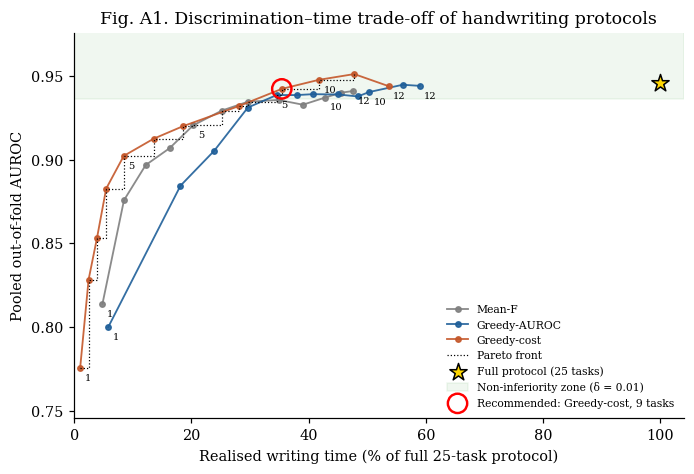

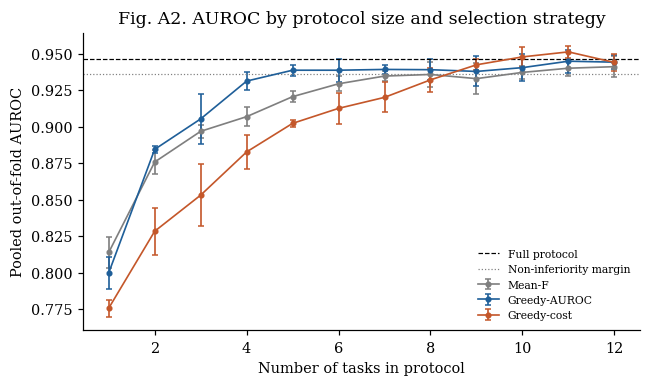

In [55]:
# ---------- Fig. A1: Pareto front AUROC × เวลา / Fig. A2: AUROC ตามจำนวน task ----------
fig, ax = plt.subplots(figsize=(6.4, 4.4))
for s in STRATEGIES:
    d = summ[summ.strategy == s].sort_values("m")
    ax.plot(d.time_frac * 100, d.AUROC, "-o", ms=3.5, lw=1.2, color=PALETTE[s], label=s, alpha=.9)
    for _, r_ in d.iterrows():
        if r_.m in (1, 5, 10) or r_.m == MAX_TASKS:
            ax.annotate(int(r_.m), (r_.time_frac * 100, r_.AUROC), fontsize=6.5, xytext=(3, -8), textcoords="offset points")
pf = cand[cand.Pareto].sort_values("time_frac")
ax.step(pf.time_frac * 100, pf.AUROC, where="post", color="black", lw=.8, ls=":", label="Pareto front")
ax.scatter([100], [full_auc], marker="*", s=140, color="gold", edgecolor="black", zorder=5, label="Full protocol (25 tasks)")
ax.axhspan(full_auc - DELTA_NI, full_auc + .05, color="green", alpha=.06, label=f"Non-inferiority zone (δ = {DELTA_NI})")
ax.scatter([REC.time_frac * 100], [REC.AUROC], s=160, facecolor="none", edgecolor="red", lw=1.6, zorder=6,
           label=f"Recommended: {REC_STRATEGY}, {REC_M} tasks")
ax.set(xlabel="Realised writing time (% of full 25-task protocol)", ylabel="Pooled out-of-fold AUROC",
       title="Fig. A1. Discrimination–time trade-off of handwriting protocols", xlim=(0, 104),
       ylim=(max(0.5, summ.AUROC.min() - .03), min(1.005, full_auc + .03)))
ax.legend(fontsize=7, loc="lower right"); fig.tight_layout(); savefig(fig, "FigA1_Pareto_AUROC_time"); plt.show()

fig, ax = plt.subplots(figsize=(6.0, 3.6))
for s in STRATEGIES:
    d = summ[summ.strategy == s].sort_values("m")
    ax.errorbar(d.m, d.AUROC, yerr=d.AUROC_sd, fmt="-o", ms=3, lw=1.1, capsize=2, color=PALETTE[s], label=s)
ax.axhline(full_auc, color="black", ls="--", lw=.8, label="Full protocol")
ax.axhline(full_auc - DELTA_NI, color="grey", ls=":", lw=.8, label="Non-inferiority margin")
ax.set(xlabel="Number of tasks in protocol", ylabel="Pooled out-of-fold AUROC",
       title="Fig. A2. AUROC by protocol size and selection strategy")
ax.legend(fontsize=7); fig.tight_layout(); savefig(fig, "FigA2_AUROC_by_size"); plt.show()

Table A2. Selection stability (Nogueira et al., 2018) across all outer folds; 1 = identical subsets


m,2,3,4,5,6,7,8,9,10,11,12
Mean-F,0.736,0.704,0.680,0.705,0.680,0.711,0.704,0.701,0.733,0.745,0.753
Greedy-AUROC,0.249,0.199,0.226,0.190,0.148,0.110,0.104,0.099,0.081,0.082,0.080
Greedy-cost,0.260,0.340,0.368,0.343,0.265,0.210,0.205,0.183,0.160,0.153,0.138


Table A3. Task-selection frequency for the recommended protocol (Greedy-cost, m = 9) across 15 outer training folds


,Task,Selection frequency,Time share (%)
0,16,0.866667,1.3
1,19,0.800000,14.3
2,8,0.666667,1.2
3,9,0.666667,1.7
4,18,0.666667,0.8
5,7,0.600000,1.9
6,13,0.600000,1.2
7,6,0.466667,1.7
8,10,0.466667,1.0
9,2,0.400000,2.6



Deployable protocol (เลือกจากข้อมูลทั้งหมด): tasks [3, 7, 8, 9, 12, 16, 18, 19, 22] — เวลาเฉลี่ย 29.7% ของ protocol เต็ม


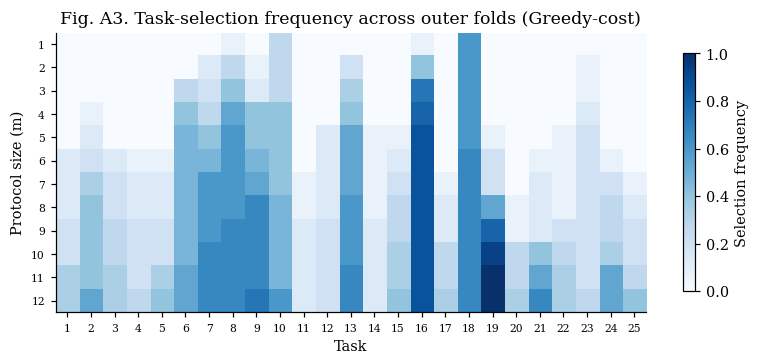

In [56]:
# ---------- Table A2: ความเสถียร (Nogueira index) / Table A3 + Fig. A3: ความถี่การเลือก task ----------
def nogueira(Z):
    M, d = Z.shape; p = Z.mean(0); kbar = Z.sum(1).mean()
    denom = (kbar / d) * (1 - kbar / d)
    return np.nan if M < 2 or denom <= 0 else 1 - (M / (M - 1) * p * (1 - p)).mean() / denom

selA = A["selections"]
def zmat(s, m):
    sub = selA[(selA.strategy == s) & (selA.m == m)]
    return np.array([[t in tasks for t in TASKS] for tasks in sub.tasks], dtype=float)

tableA2 = pd.DataFrame({s: {m: nogueira(zmat(s, m)) for m in range(2, MAX_TASKS + 1)} for s in STRATEGIES}).round(3)
tableA2.index.name = "m"
print("Table A2. Selection stability (Nogueira et al., 2018) across all outer folds; 1 = identical subsets")
display(tableA2.T)

Zrec = zmat(REC_STRATEGY, REC_M)
freq = pd.Series(Zrec.mean(0), index=TASKS)
tableA3 = (pd.DataFrame({"Task": TASKS, "Selection frequency": freq.values,
                         "Time share (%)": (time_share[TASKS] * 100).round(1).values})
           .query("`Selection frequency` > 0").sort_values(["Selection frequency", "Task"], ascending=[False, True])
           .reset_index(drop=True))
print(f"Table A3. Task-selection frequency for the recommended protocol ({REC_STRATEGY}, m = {REC_M}) "
      f"across {len(Zrec)} outer training folds")
display(tableA3)

# Deployable protocol: รันกลยุทธ์ที่แนะนำบนข้อมูลทั้งหมด (ต้องยืนยันด้วยข้อมูลภายนอก)
inner_all = inner_splits(y, SEED_BASE + 999)
DEPLOY_TASKS = sorted(int(t) for t in select_path(REC_STRATEGY, X_np, y, inner_all, REC_M)[REC_M - 1])
DEPLOY_TIME = realized_time_frac(X_np, DEPLOY_TASKS).mean()
print(f"\nDeployable protocol (เลือกจากข้อมูลทั้งหมด): tasks {DEPLOY_TASKS} — "
      f"เวลาเฉลี่ย {DEPLOY_TIME * 100:.1f}% ของ protocol เต็ม")

H = np.vstack([zmat(REC_STRATEGY, m).mean(0) for m in range(1, MAX_TASKS + 1)])
fig, ax = plt.subplots(figsize=(7.4, 3.4))
im = ax.imshow(H, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(TASKS)), TASKS, fontsize=7); ax.set_yticks(range(MAX_TASKS), range(1, MAX_TASKS + 1), fontsize=7)
ax.set(xlabel="Task", ylabel="Protocol size (m)",
       title=f"Fig. A3. Task-selection frequency across outer folds ({REC_STRATEGY})")
fig.colorbar(im, ax=ax, label="Selection frequency", shrink=.85)
fig.tight_layout(); savefig(fig, "FigA3_selection_frequency"); plt.show()

---
# ส่วน E — Calibration, conformal prediction และประโยชน์ทางคลินิก (RQ3)
เปรียบเทียบสองระบบ: **Full** (25 tasks) และ **Reduced** (กลยุทธ์และขนาดที่แนะนำจากส่วน A โดย *เลือก task ใหม่ภายในทุก outer training fold*)

ภายในแต่ละ outer fold ใช้ **inner OOF probabilities ของ training data** (ไม่ใช้ข้อมูล outer test) สำหรับ
1. **Recalibration:** Platt scaling (logistic บน logit *p*) และ isotonic regression
2. **Mondrian (class-conditional) cross-conformal prediction:** nonconformity $s = 1-\hat p(y\mid x)$ และ quantile แยกตามคลาส
   $\hat q_c = \text{Quantile}\big(s_{c};\ \lceil (n_c+1)(1-\alpha)\rceil / n_c\big)$ — prediction set $= \{c : 1-\hat p(c\mid x) \le \hat q_c\}$
3. **Threshold ทางคลินิก:** threshold ที่ให้ความไว ≥ 0.90 และ Youden threshold

แล้วประเมินบน outer test fold: calibration (Brier, ECE, calibration slope, calibration-in-the-large), conformal coverage และขนาด set,
selective prediction (risk–coverage) และ **decision-curve analysis ภายใต้ prevalence ของการคัดกรองจริง** โดยปรับความน่าจะเป็นด้วย prior shift

$$\text{logit}\,p_\pi = \text{logit}\,p + \log\tfrac{\pi}{1-\pi} - \log\tfrac{\pi_0}{1-\pi_0},\qquad
\text{NB}(p_t) = \text{Sens}\cdot\pi - (1-\text{Spec})(1-\pi)\tfrac{p_t}{1-p_t}$$

> **ข้อควรระบุในบทความ:** cross-conformal ให้ coverage ใกล้ค่าที่กำหนดในทางปฏิบัติ แต่การรับประกันเชิงทฤษฎีขั้นต่ำคือ $1-2\alpha$ (Barber et al., 2021)

In [57]:
def conformal_sets(p_cal, y_cal, p_te, alpha):
    q = {}
    for c in (0, 1):
        s = (1 - p_cal[y_cal == 1]) if c == 1 else p_cal[y_cal == 0]
        n_c = len(s); lvl = np.ceil((n_c + 1) * (1 - alpha)) / n_c
        q[c] = np.inf if lvl > 1 else np.quantile(s, lvl, method="higher")
    return (p_te <= q[0]), ((1 - p_te) <= q[1])          # มีคลาส 0 ใน set?, มีคลาส 1 ใน set?

def thr_for_sens(p, yy, target):
    pos = np.sort(p[yy == 1])                                # threshold สูงสุดที่ยังได้ sens ≥ target
    return pos[int(np.floor((1 - target) * len(pos)))]

def thr_youden(p, yy):
    cands = np.unique(p)
    j = [((p[yy == 1] >= t).mean() + (p[yy == 0] < t).mean() - 1) for t in cands]
    return cands[int(np.argmax(j))]

def run_E():
    out = []
    for r in range(N_REPEATS_E):
        seed = SEED_BASE + r
        res = {sys: {"p_raw": np.zeros(N), "p_platt": np.zeros(N), "p_iso": np.zeros(N),
                     "thr_sens": np.zeros(N), "thr_youden": np.zeros(N), "tasks": [],
                     **{f"in0_{a}": np.zeros(N, bool) for a in ALPHAS}, **{f"in1_{a}": np.zeros(N, bool) for a in ALPHAS}}
               for sys in ("Full", "Reduced")}
        for f, (tr, te) in enumerate(outer_splits(seed)):
            Xtr, ytr, Xte = X_np[tr], y[tr], X_np[te]
            inner = inner_splits(ytr, seed + 100 + f)
            red_tasks = select_path(REC_STRATEGY, Xtr, ytr, inner, REC_M)[REC_M - 1]
            for sys, cols in (("Full", ALL_COLS), ("Reduced", cols_of(red_tasks))):
                R = res[sys]; R["tasks"].append(sorted(red_tasks) if sys == "Reduced" else "all")
                #p_in = inner_oof("RF", FIXED["RF"], Xtr[:, cols], ytr, inner, seed)
                if sys == "Reduced":       # เลือก task ใหม่ภายในทุก inner split เพื่อไม่ให้ calibration scores มี selection optimism
                    p_in = np.zeros(len(ytr))
                    for a, b in inner:
                        inner2 = inner_splits(ytr[a], seed + 500 + f)
                        c_in = cols_of(select_path(REC_STRATEGY, Xtr[a], ytr[a], inner2, REC_M)[REC_M - 1])
                        p_in[b] = fit_predict("RF", FIXED["RF"], Xtr[a][:, c_in], ytr[a], Xtr[b][:, c_in], seed)
                else:
                    p_in = inner_oof("RF", FIXED["RF"], Xtr[:, cols], ytr, inner, seed)
                p_te = fit_predict("RF", FIXED["RF"], Xtr[:, cols], ytr, Xte[:, cols], seed)
                platt = LogisticRegression(C=1e6, max_iter=5000).fit(logit(p_in).reshape(-1, 1), ytr)
                iso = IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(p_in, ytr)
                R["p_raw"][te] = p_te
                R["p_platt"][te] = platt.predict_proba(logit(p_te).reshape(-1, 1))[:, 1]
                R["p_iso"][te] = iso.predict(p_te)
                R["thr_sens"][te] = thr_for_sens(p_in, ytr, SENS_TARGET)
                R["thr_youden"][te] = thr_youden(p_in, ytr)
                for a in ALPHAS:
                    i0, i1 = conformal_sets(p_in, ytr, p_te, a)
                    R[f"in0_{a}"][te] = i0; R[f"in1_{a}"][te] = i1
        out.append(res); print(f"  repeat {r + 1}/{N_REPEATS_E} เสร็จ")
    return out

#E = cached(f"E_{REC_STRATEGY}_{REC_M}", run_E)
E = cached(f"E_{REC_STRATEGY}_{REC_M}_v2", run_E)
SYS_LABEL = {"Full": "Full protocol (25 tasks)", "Reduced": f"Reduced protocol ({REC_STRATEGY}, {REC_M} tasks)"}

โหลดผลจาก cache: outputs/cache/E_Greedy-cost_9_v2_full.pkl


Table E1. Calibration of out-of-fold probabilities (mean ± SD over 5 repetitions)


,System,Calibration,AUROC,Brier,ECE,Calibration slope,Calibration-in-the-large
0,Full protocol (25 tasks),Uncalibrated,0.942 ± 0.007,0.109 ± 0.004,0.101 ± 0.012,2.068 ± 0.174,0.035 ± 0.037
1,Full protocol (25 tasks),Platt,0.941 ± 0.006,0.101 ± 0.005,0.042 ± 0.011,0.940 ± 0.094,0.028 ± 0.105
2,Full protocol (25 tasks),Isotonic,0.927 ± 0.007,0.109 ± 0.007,0.061 ± 0.013,0.469 ± 0.083,0.006 ± 0.080
3,"Reduced protocol (Greedy-cost, 9 tasks)",Uncalibrated,0.933 ± 0.013,0.116 ± 0.007,0.104 ± 0.017,2.110 ± 0.210,0.013 ± 0.030
4,"Reduced protocol (Greedy-cost, 9 tasks)",Platt,0.932 ± 0.011,0.106 ± 0.010,0.046 ± 0.017,1.060 ± 0.143,0.010 ± 0.117
5,"Reduced protocol (Greedy-cost, 9 tasks)",Isotonic,0.922 ± 0.011,0.113 ± 0.010,0.051 ± 0.012,0.635 ± 0.169,-0.019 ± 0.143


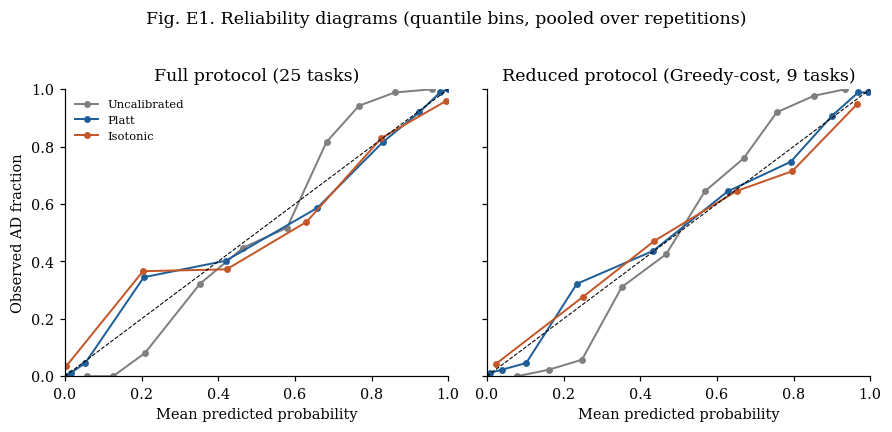

In [58]:
# ---------- Table E1 + Fig. E1: Calibration ----------
def calib_metrics(yy, p):
    p = np.clip(p, EPS, 1 - EPS); lp = logit(p)
    edges = np.unique(np.quantile(p, np.linspace(0, 1, 11)))
    b = np.clip(np.digitize(p, edges[1:-1]), 0, len(edges) - 2)
    ece = sum(abs(yy[b == k].mean() - p[b == k].mean()) * (b == k).mean() for k in np.unique(b))
    try:
        slope = sm.GLM(yy, sm.add_constant(lp), family=sm.families.Binomial()).fit().params[1]
        citl = sm.GLM(yy, np.ones_like(lp), family=sm.families.Binomial(), offset=lp).fit().params[0]
    except Exception:
        slope = citl = np.nan
    return {"AUROC": roc_auc_score(yy, p), "Brier": brier_score_loss(yy, p), "ECE": ece,
            "Calibration slope": slope, "Calibration-in-the-large": citl}

rows = []
for sys in ("Full", "Reduced"):
    for kind, lab in (("p_raw", "Uncalibrated"), ("p_platt", "Platt"), ("p_iso", "Isotonic")):
        mets = pd.DataFrame([calib_metrics(y, rep[sys][kind]) for rep in E])
        rows.append({"System": SYS_LABEL[sys], "Calibration": lab, **{k: mean_sd(mets[k]) for k in mets}})
tableE1 = pd.DataFrame(rows)
print(f"Table E1. Calibration of out-of-fold probabilities (mean ± SD over {N_REPEATS_E} repetitions)")
display(tableE1)

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.8), sharey=True)
for ax, sys in zip(axes, ("Full", "Reduced")):
    for kind, lab, col in (("p_raw", "Uncalibrated", "#7f7f7f"), ("p_platt", "Platt", "#1f5f99"), ("p_iso", "Isotonic", "#c4572a")):
        p = np.concatenate([rep[sys][kind] for rep in E]); yy = np.tile(y, len(E))
        edges = np.unique(np.quantile(p, np.linspace(0, 1, 11))); b = np.clip(np.digitize(p, edges[1:-1]), 0, len(edges) - 2)
        mp = [p[b == k].mean() for k in np.unique(b)]; ob = [yy[b == k].mean() for k in np.unique(b)]
        ax.plot(mp, ob, "-o", ms=3.5, lw=1.3, color=col, label=lab)
    ax.plot([0, 1], [0, 1], ls="--", color="black", lw=.7)
    ax.set(xlabel="Mean predicted probability", title=SYS_LABEL[sys], xlim=(0, 1), ylim=(0, 1))
axes[0].set_ylabel("Observed AD fraction"); axes[0].legend(fontsize=7.5)
fig.suptitle("Fig. E1. Reliability diagrams (quantile bins, pooled over repetitions)", y=1.02)
fig.tight_layout(); savefig(fig, "FigE1_reliability"); plt.show()

Table E2. Mondrian cross-conformal prediction on outer test folds (mean ± SD over repetitions)


,System,α,Nominal,Coverage,Coverage AD,Coverage HC,Mean set size,Singleton (%),"Ambiguous {AD,HC} (%)",Empty (%),Referral (%),Singleton accuracy
0,Full protocol (25 tasks),0.05,0.95,0.969 ± 0.009,0.966 ± 0.011,0.972 ± 0.013,1.340 ± 0.031,65.977 ± 3.079,34.023 ± 3.079,0.000 ± 0.000,34.023 ± 3.079,0.953 ± 0.011
1,Full protocol (25 tasks),0.10,0.90,0.918 ± 0.011,0.897 ± 0.020,0.941 ± 0.008,1.159 ± 0.027,84.138 ± 2.714,15.862 ± 2.714,0.000 ± 0.000,15.862 ± 2.714,0.903 ± 0.010
2,Full protocol (25 tasks),0.20,0.80,0.831 ± 0.009,0.825 ± 0.023,0.838 ± 0.013,0.963 ± 0.016,94.713 ± 0.749,0.805 ± 0.872,4.483 ± 0.852,5.287 ± 0.749,0.869 ± 0.006
3,"Reduced protocol (Greedy-cost, 9 tasks)",0.05,0.95,0.983 ± 0.007,0.982 ± 0.017,0.984 ± 0.013,1.445 ± 0.051,55.517 ± 5.085,44.483 ± 5.085,0.000 ± 0.000,44.483 ± 5.085,0.969 ± 0.011
4,"Reduced protocol (Greedy-cost, 9 tasks)",0.10,0.90,0.932 ± 0.019,0.926 ± 0.028,0.939 ± 0.026,1.237 ± 0.033,76.322 ± 3.336,23.678 ± 3.336,0.000 ± 0.000,23.678 ± 3.336,0.912 ± 0.021
5,"Reduced protocol (Greedy-cost, 9 tasks)",0.20,0.80,0.840 ± 0.020,0.836 ± 0.029,0.845 ± 0.019,0.992 ± 0.034,95.287 ± 2.827,1.954 ± 1.974,2.759 ± 2.418,4.713 ± 2.827,0.861 ± 0.020


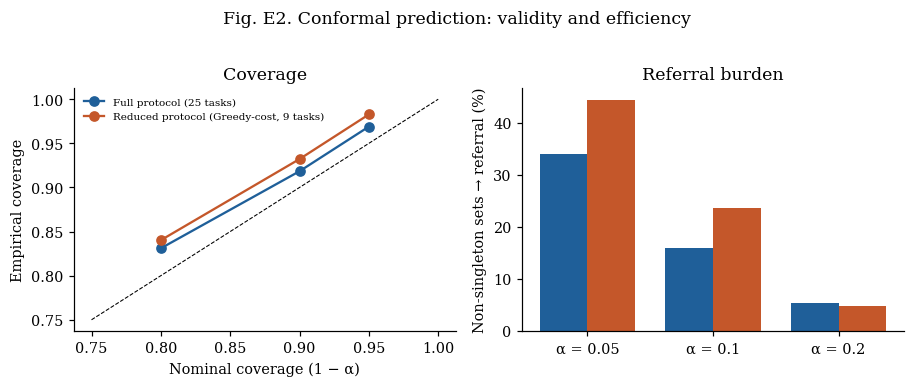

In [59]:
# ---------- Table E2 + Fig. E2: Mondrian cross-conformal prediction ----------
rows = []
for sys in ("Full", "Reduced"):
    for a in ALPHAS:
        recs = []
        for rep in E:
            i0, i1 = rep[sys][f"in0_{a}"], rep[sys][f"in1_{a}"]
            cover = np.where(y == 1, i1, i0); size = i0.astype(int) + i1.astype(int)
            single = size == 1; pred_single = np.where(i1, 1, 0)
            recs.append({"Coverage": cover.mean(), "Coverage AD": cover[y == 1].mean(), "Coverage HC": cover[y == 0].mean(),
                         "Mean set size": size.mean(), "Singleton (%)": 100 * single.mean(),
                         "Ambiguous {AD,HC} (%)": 100 * (size == 2).mean(), "Empty (%)": 100 * (size == 0).mean(),
                         "Referral (%)": 100 * (size != 1).mean(),
                         "Singleton accuracy": (pred_single[single] == y[single]).mean() if single.any() else np.nan})
        recs = pd.DataFrame(recs)
        rows.append({"System": SYS_LABEL[sys], "α": a, "Nominal": 1 - a, **{k: mean_sd(recs[k], 3) for k in recs}})
tableE2 = pd.DataFrame(rows)
print("Table E2. Mondrian cross-conformal prediction on outer test folds (mean ± SD over repetitions)")
display(tableE2)

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.4))
for k, sys in enumerate(("Full", "Reduced")):
    cov = [np.mean([np.where(y == 1, rep[sys][f"in1_{a}"], rep[sys][f"in0_{a}"]).mean() for rep in E]) for a in ALPHAS]
    axes[0].plot([1 - a for a in ALPHAS], cov, "-o", color=PALETTE[sys], label=SYS_LABEL[sys])
    amb = [np.mean([(rep[sys][f"in0_{a}"] == rep[sys][f"in1_{a}"]).mean() for rep in E]) * 100 for a in ALPHAS]
    axes[1].bar(np.arange(len(ALPHAS)) + (k - .5) * .38, amb, width=.38, color=PALETTE[sys], label=SYS_LABEL[sys])
axes[0].plot([.75, 1], [.75, 1], "k--", lw=.7)
axes[0].set(xlabel="Nominal coverage (1 − α)", ylabel="Empirical coverage", title="Coverage")
axes[1].set_xticks(range(len(ALPHAS)), [f"α = {a}" for a in ALPHAS])
axes[1].set(ylabel="Non-singleton sets → referral (%)", title="Referral burden")
axes[0].legend(fontsize=6.8); fig.suptitle("Fig. E2. Conformal prediction: validity and efficiency", y=1.02)
fig.tight_layout(); savefig(fig, "FigE2_conformal"); plt.show()

Table E3. Selective prediction: accuracy when the least-confident cases are referred (Platt-calibrated)


,System,AURC (lower = better),Accuracy @ 100% coverage,Accuracy @ 90% coverage,Accuracy @ 80% coverage,Accuracy @ 70% coverage
0,Full protocol (25 tasks),0.0367 ± 0.0049,0.851 ± 0.015,0.887 ± 0.008,0.919 ± 0.008,0.944 ± 0.015
1,"Reduced protocol (Greedy-cost, 9 tasks)",0.0435 ± 0.0073,0.845 ± 0.026,0.878 ± 0.021,0.906 ± 0.020,0.938 ± 0.015


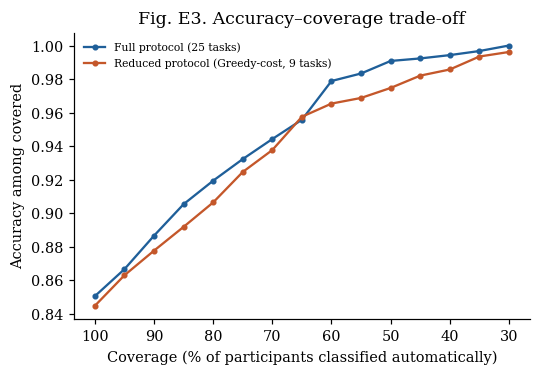

In [60]:
# ---------- Table E3 + Fig. E3: Selective prediction (risk–coverage) ----------
COVS = np.linspace(0.3, 1.0, 15)
def risk_coverage(p, yy):
    conf = np.maximum(p, 1 - p); order = np.argsort(-conf, kind="stable")
    correct = ((p >= .5).astype(int) == yy)[order]
    accs = [correct[:max(1, int(round(c * len(yy))))].mean() for c in COVS]
    full_curve = np.cumsum(1 - correct) / np.arange(1, len(yy) + 1)
    return np.array(accs), full_curve.mean()               # accuracy ตาม coverage, AURC

rows, curves = [], {}
for sys in ("Full", "Reduced"):
    accs, aurcs = zip(*[risk_coverage(rep[sys]["p_platt"], y) for rep in E])
    accs = np.vstack(accs); curves[sys] = accs.mean(0)
    row = {"System": SYS_LABEL[sys], "AURC (lower = better)": mean_sd(aurcs, 4)}
    for c in (1.0, 0.9, 0.8, 0.7):
        j = int(np.argmin(abs(COVS - c))); row[f"Accuracy @ {int(c * 100)}% coverage"] = mean_sd(accs[:, j])
    rows.append(row)
tableE3 = pd.DataFrame(rows)
print("Table E3. Selective prediction: accuracy when the least-confident cases are referred (Platt-calibrated)")
display(tableE3)

fig, ax = plt.subplots(figsize=(5.0, 3.5))
for sys in ("Full", "Reduced"):
    ax.plot(COVS * 100, curves[sys], "-o", ms=3, color=PALETTE[sys], label=SYS_LABEL[sys])
ax.set(xlabel="Coverage (% of participants classified automatically)", ylabel="Accuracy among covered",
       title="Fig. E3. Accuracy–coverage trade-off")
ax.invert_xaxis(); ax.legend(fontsize=7); fig.tight_layout(); savefig(fig, "FigE3_risk_coverage"); plt.show()

Table E4. Operating characteristics at training-derived thresholds and implied predictive values


,System,Threshold rule,Sensitivity,Specificity,PPV @ π=0.05,NPV @ π=0.05,PPV @ π=0.1,NPV @ π=0.1,PPV @ π=0.2,NPV @ π=0.2
0,Full protocol (25 tasks),Sensitivity-targeted (≥0.90 in training),0.876 ± 0.016,0.814 ± 0.021,0.200 ± 0.018,0.992 ± 0.001,0.345 ± 0.025,0.983 ± 0.002,0.542 ± 0.028,0.963 ± 0.005
1,Full protocol (25 tasks),Youden,0.834 ± 0.046,0.854 ± 0.031,0.235 ± 0.029,0.990 ± 0.003,0.392 ± 0.040,0.979 ± 0.005,0.591 ± 0.041,0.954 ± 0.012
2,"Reduced protocol (Greedy-cost, 9 tasks)",Sensitivity-targeted (≥0.90 in training),0.899 ± 0.032,0.779 ± 0.030,0.178 ± 0.023,0.993 ± 0.002,0.313 ± 0.034,0.986 ± 0.004,0.506 ± 0.038,0.969 ± 0.010
3,"Reduced protocol (Greedy-cost, 9 tasks)",Youden,0.825 ± 0.042,0.845 ± 0.042,0.225 ± 0.039,0.989 ± 0.002,0.378 ± 0.054,0.978 ± 0.005,0.576 ± 0.058,0.951 ± 0.010


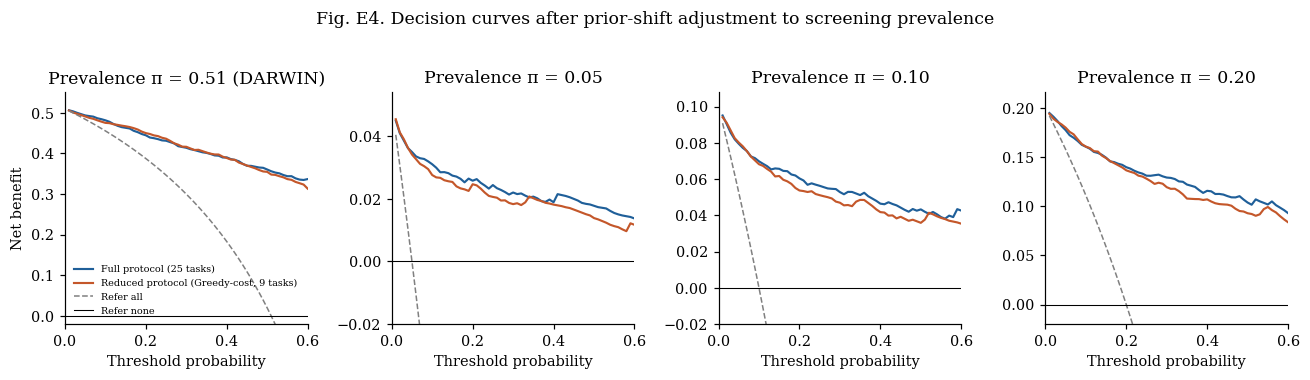

In [61]:
# ---------- Table E4: Threshold ทางคลินิก + PPV/NPV ภายใต้ prevalence จริง / Fig. E4: Decision curves ----------
def ppv_npv(sens, spec, pi):
    return sens * pi / (sens * pi + (1 - spec) * (1 - pi)), spec * (1 - pi) / (spec * (1 - pi) + (1 - sens) * pi)

rows = []
for sys in ("Full", "Reduced"):
    for thr_key, lab in (("thr_sens", f"Sensitivity-targeted (≥{SENS_TARGET:.2f} in training)"), ("thr_youden", "Youden")):
        recs = []
        for rep in E:
            yhat = (rep[sys]["p_raw"] >= rep[sys][thr_key]).astype(int)
            tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
            se, sp = tp / (tp + fn), tn / (tn + fp); rec = {"Sensitivity": se, "Specificity": sp}
            for pi in PREVALENCES:
                pv, nv = ppv_npv(se, sp, pi); rec[f"PPV @ π={pi}"] = pv; rec[f"NPV @ π={pi}"] = nv
            recs.append(rec)
        recs = pd.DataFrame(recs)
        rows.append({"System": SYS_LABEL[sys], "Threshold rule": lab, **{k: mean_sd(recs[k]) for k in recs}})
tableE4 = pd.DataFrame(rows)
print("Table E4. Operating characteristics at training-derived thresholds and implied predictive values")
display(tableE4)

PT = np.linspace(0.01, 0.60, 60)
def net_benefit(p, yy, pi, pt):
    pp = expit(logit(p) + np.log(pi / (1 - pi)) - np.log(PI0 / (1 - PI0)))
    se = (pp[yy == 1] >= pt).mean(); sp = (pp[yy == 0] < pt).mean()
    return se * pi - (1 - sp) * (1 - pi) * pt / (1 - pt)

fig, axes = plt.subplots(1, len(PREVALENCES) + 1, figsize=(12, 3.3), sharey=False)
NB_SUMMARY = {}
for ax, pi in zip(axes, [round(PI0, 2)] + PREVALENCES):
    for sys in ("Full", "Reduced"):
        nb = np.mean([[net_benefit(rep[sys]["p_platt"], y, pi, t) for t in PT] for rep in E], axis=0)
        ax.plot(PT, nb, color=PALETTE[sys], lw=1.4, label=SYS_LABEL[sys]); NB_SUMMARY[(sys, pi)] = (PT, nb)
    ax.plot(PT, pi - (1 - pi) * PT / (1 - PT), color="grey", lw=1, ls="--", label="Refer all")
    ax.axhline(0, color="black", lw=.7, label="Refer none")
    ax.set(xlim=(0, PT.max()), ylim=(-0.02, pi * 1.08), xlabel="Threshold probability",
           title=f"Prevalence π = {pi:.2f}" + (" (DARWIN)" if pi == round(PI0, 2) else ""))
axes[0].set_ylabel("Net benefit"); axes[0].legend(fontsize=6.3)
fig.suptitle("Fig. E4. Decision curves after prior-shift adjustment to screening prevalence", y=1.03)
fig.tight_layout(); savefig(fig, "FigE4_decision_curves"); plt.show()

---
# ส่วน S — ส่งออกผลลัพธ์และร่างข้อความสำหรับบทความ
เซลล์ถัดไปรวมทุกตารางเป็นไฟล์ Excel และสร้าง **ร่าง Methods และ Results ภาษาอังกฤษ** ที่เติมตัวเลขจากการวิเคราะห์โดยอัตโนมัติ
(`outputs/manuscript_draft.md`) — ควรตรวจทานและปรับถ้อยคำก่อนใช้งานจริง

In [62]:
with pd.ExcelWriter(f"{OUT_DIR}/Phase1_results.xlsx") as xw:
    for name, t in [("D1_performance", tableD1), ("D2_optimism", tableD2.drop(columns="_mean")), ("D3_bayes", tableD3),
                    ("A1_protocols", tableA1), ("A2_stability", tableA2.T.reset_index()), ("A3_task_freq", tableA3),
                    ("E1_calibration", tableE1), ("E2_conformal", tableE2), ("E3_selective", tableE3),
                    ("E4_thresholds", tableE4)]:
        t.to_excel(xw, sheet_name=name, index=False)
    D["pooled"].to_excel(xw, sheet_name="raw_D_pooled", index=False)
    A["pooled"].to_excel(xw, sheet_name="raw_A_pooled", index=False)
print("บันทึก:", f"{OUT_DIR}/Phase1_results.xlsx")

บันทึก: outputs/Phase1_results.xlsx


In [63]:
g = lambda m, v, k="AUROC": pD[(pD.model == m) & (pD.variant == v)][k]
d2 = {(r.Source, r.Model): r for r in tableD2.itertuples()}
best_pair = tableD3.iloc[0]; rf_lr = tableD3.iloc[1]
e1 = {(r.System, r.Calibration): r for r in tableE1.itertuples()}
e2 = tableE2.set_index(["System", "α"])
e4 = {(r.System, r._2): r for r in tableE4.itertuples()}
mf10 = summ[(summ.strategy == "Mean-F") & (summ.m == min(10, MAX_TASKS))].iloc[0]
tun_rf = d2[("Hyperparameter tuning optimism", MODEL_LABEL["RF"])]
sel_rf = d2[("Task-selection optimism (10 tasks)", MODEL_LABEL["RF"])]
gain = {m: d2[("Gain from nested tuning", MODEL_LABEL[m])].ΔAUROC for m in ("RF", "XGB", "LR")}
red, full = SYS_LABEL["Reduced"], SYS_LABEL["Full"]
a10 = 0.10 if 0.10 in ALPHAS else ALPHAS[0]

methods = f'''## Methods (draft)

**Validation design.** All analyses used repeated stratified {N_FOLDS}-fold cross-validation with an inner {N_INNER}-fold loop.
Univariate ANOVA-F feature selection, hyperparameter selection, task selection, recalibration, conformal calibration and
threshold selection were performed exclusively within outer training folds; outer test folds were used only for evaluation.
Primary model comparisons used {N_REPEATS_D} repetitions. Three evaluation variants were contrasted: a fixed configuration
reproducing a previously published specification, a nested configuration selected by inner cross-validation from a predefined
grid ({len(GRIDS["RF"])}, {len(GRIDS["XGB"])} and {len(GRIDS["LR"])} configurations for random forest, XGBoost and logistic regression,
respectively), and a best-of-grid estimate that selects the configuration with the highest outer-fold AUROC, representing tuning
on the reporting data. Tuning optimism was defined as the AUROC difference between best-of-grid and nested estimates, and
task-selection optimism as the difference between selecting ten tasks once from the complete labelled dataset and selecting them
within each training fold. Fold-level AUROC differences between nested models were assessed with the Bayesian correlated
t-test (correlation ρ = 1/{N_FOLDS}; region of practical equivalence ±{ROPE}) and the Nadeau–Bengio corrected resampled t-test.

**Cost-aware protocol selection.** The time cost of each task was defined as the median of its total execution time
(total_time) in the training fold, expressed as a proportion of the summed medians across all 25 tasks. Protocols of 1 to
{MAX_TASKS} tasks were constructed within each outer training fold using three strategies: ranking by mean task-level ANOVA-F
(Mean-F), greedy forward selection maximising inner cross-validated AUROC (Greedy-AUROC), and greedy forward selection maximising
the inner AUROC gain per unit time cost (Greedy-cost). The inner search used L2-regularised logistic regression as a fast surrogate;
selected protocols were evaluated on outer test folds with a random forest. Realised time was computed for outer-test participants
as the proportion of their total writing time contributed by the selected tasks. The recommended protocol was the one with the
lowest realised time whose mean AUROC difference from the full protocol was no worse than −{DELTA_NI} (non-inferiority margin).
Selection stability was quantified with the Nogueira stability index. Analyses in this section used {N_REPEATS_A} repetition(s).

**Uncertainty quantification and clinical utility.** For the full and recommended reduced protocols ({N_REPEATS_E} repetitions),
inner out-of-fold probabilities from each outer training fold were used to fit Platt and isotonic recalibration, Mondrian
(class-conditional) cross-conformal predictors with nonconformity score 1 − p̂(y|x) at α ∈ {{{", ".join(map(str, ALPHAS))}}}, and
operating thresholds (sensitivity ≥ {SENS_TARGET:.2f} and Youden index). Calibration was summarised by the Brier score, expected
calibration error (ten quantile bins), calibration slope and calibration-in-the-large. Selective prediction was evaluated by the
area under the risk–coverage curve. Decision-curve analysis was performed after prior-shift adjustment of calibrated probabilities
to screening prevalences of {", ".join(f"{p:.0%}" for p in PREVALENCES)}, and predictive values at these prevalences were derived
from the outer-fold sensitivity and specificity.
'''

results = f'''## Results (draft)

**Evaluation optimism and model comparison.** Under repeated nested cross-validation, random forest achieved a pooled AUROC of
{mean_sd(g("RF", "Nested"))}, compared with {mean_sd(g("XGB", "Nested"))} for XGBoost and {mean_sd(g("LR", "Nested"))} for logistic
regression (Table D1). Selecting the best configuration on the reporting folds inflated random-forest AUROC by {tun_rf.ΔAUROC}
(positive in {tun_rf._5} repetitions), and selecting tasks from the complete labelled dataset inflated the ten-task AUROC by
{sel_rf.ΔAUROC} (positive in {sel_rf._5} repetitions; Table D2). Nested tuning relative to the fixed published configuration changed
AUROC by {gain["RF"]}, {gain["XGB"]} and {gain["LR"]} for random forest, XGBoost and logistic regression, respectively. The posterior
probability that random forest exceeded XGBoost by more than the ROPE was {best_pair["P(A better)"]:.3f}, with a probability of
practical equivalence of {best_pair["P(ROPE)"]:.3f}; the corresponding probabilities for random forest versus logistic regression were
{rf_lr["P(A better)"]:.3f} and {rf_lr["P(ROPE)"]:.3f} (Table D3).

**Cost-aware protocol selection.** The full 25-task protocol yielded AUROC {full_auc:.3f}. The recommended protocol
({REC_STRATEGY}, {REC_M} tasks) required {REC.time_frac * 100:.1f}% of the full writing time (a {(1 - REC.time_frac) * 100:.1f}% reduction)
with an AUROC difference of {REC.dAUROC:+.4f} (Table A1; Fig. A1). For comparison, the ten-task Mean-F protocol, corresponding to the
previously published selection rule, required {mf10.time_frac * 100:.1f}% of the full writing time and changed AUROC by {mf10.dAUROC:+.4f}.
The protocol with the fewest tasks meeting the non-inferiority criterion ({REC_FEWEST.strategy}, {int(REC_FEWEST.m)} tasks) required
{REC_FEWEST.time_frac * 100:.1f}% of the writing time, illustrating that task count and time burden are not interchangeable.
Selection stability at the recommended size was Φ = {tableA2.loc[max(2, REC_M), REC_STRATEGY]:.3f} (Table A2). Applied to the
complete dataset, the recommended strategy selected tasks {", ".join(map(str, DEPLOY_TASKS))}, accounting for
{DEPLOY_TIME * 100:.1f}% of total writing time; this protocol is proposed for external confirmation rather than as a validated battery.

**Calibration, conformal prediction and clinical utility.** Platt recalibration yielded Brier scores of
{e1[(full, "Platt")].Brier} and {e1[(red, "Platt")].Brier} and calibration slopes of {e1[(full, "Platt")]._6} and
{e1[(red, "Platt")]._6} for the full and reduced protocols, respectively (Table E1). At α = {a10}, Mondrian cross-conformal prediction
achieved empirical coverage of {e2.loc[(full, a10), "Coverage"]} (full) and {e2.loc[(red, a10), "Coverage"]} (reduced), with
{e2.loc[(full, a10), "Referral (%)"]}% and {e2.loc[(red, a10), "Referral (%)"]}% of participants receiving non-singleton
(ambiguous or empty) prediction sets that would be referred for clinical assessment (Table E2). Accuracy among singleton predictions was
{e2.loc[(full, a10), "Singleton accuracy"]} and {e2.loc[(red, a10), "Singleton accuracy"]}, respectively. At the training-derived
sensitivity-targeted threshold, the reduced protocol achieved sensitivity {e4[(red, f"Sensitivity-targeted (≥{SENS_TARGET:.2f} in training)")].Sensitivity}
and specificity {e4[(red, f"Sensitivity-targeted (≥{SENS_TARGET:.2f} in training)")].Specificity}; at a screening prevalence of
{PREVALENCES[0]:.0%}, the implied positive predictive value was {getattr(e4[(red, f"Sensitivity-targeted (≥{SENS_TARGET:.2f} in training)")], "_5")}
(Table E4), indicating that handwriting-based classification is better suited to triage than to standalone diagnosis in
low-prevalence settings. Decision curves are shown in Fig. E4.
'''
with open(f"{OUT_DIR}/manuscript_draft.md", "w", encoding="utf-8") as fh:
    fh.write(methods + "\n" + results)
print(methods); print(results)

## Methods (draft)

**Validation design.** All analyses used repeated stratified 5-fold cross-validation with an inner 5-fold loop.
Univariate ANOVA-F feature selection, hyperparameter selection, task selection, recalibration, conformal calibration and
threshold selection were performed exclusively within outer training folds; outer test folds were used only for evaluation.
Primary model comparisons used 10 repetitions. Three evaluation variants were contrasted: a fixed configuration
reproducing a previously published specification, a nested configuration selected by inner cross-validation from a predefined
grid (6, 8 and 9 configurations for random forest, XGBoost and logistic regression,
respectively), and a best-of-grid estimate that selects the configuration with the highest outer-fold AUROC, representing tuning
on the reporting data. Tuning optimism was defined as the AUROC difference between best-of-grid and nested estimates, and
task-selection optimism as the difference between 

In [64]:
# =====================================================================================
# Phase 1b — เซลล์เสริม 2 เซลล์ สำหรับวางต่อท้าย Phase1_DARWIN_CostAware_Uncertainty.ipynb
# ต้องรันหลังส่วน E ฉบับแก้ไข (v2: เลือก task ใหม่ใน inner split) และใช้ REC_STRATEGY / REC_M เดิม
# เซลล์ 1 (Table S1): ~10–15 นาที  |  เซลล์ 2 (Tables S2–S3, B_CONS = 10): ~45–90 นาที บน Colab CPU
# =====================================================================================

# %% [เซลล์ 1] Leakage → conformal coverage, protocol เดียวกัน
# ===== Phase 1b-1: เทียบ coverage ของ protocol เดียวกัน เมื่อ "ไม่" เลือก task ใหม่ใน inner split (v1) กับ "เลือกใหม่" (v2) =====
# v1 = เลือก task ครั้งเดียวจาก outer training fold แล้วใช้ชุดเดียวกันคำนวณ calibration scores (มี selection leakage)
def run_E_v1():
    out = []
    for r in range(N_REPEATS_E):
        seed = SEED_BASE + r
        R = {**{f"in0_{a}": np.zeros(N, bool) for a in ALPHAS}, **{f"in1_{a}": np.zeros(N, bool) for a in ALPHAS}}
        for f, (tr, te) in enumerate(outer_splits(seed)):
            Xtr, ytr, Xte = X_np[tr], y[tr], X_np[te]
            inner = inner_splits(ytr, seed + 100 + f)
            cols = cols_of(select_path(REC_STRATEGY, Xtr, ytr, inner, REC_M)[REC_M - 1])
            p_in = inner_oof("RF", FIXED["RF"], Xtr[:, cols], ytr, inner, seed)     # task ชุดเดิม → leakage
            p_te = fit_predict("RF", FIXED["RF"], Xtr[:, cols], ytr, Xte[:, cols], seed)
            for a in ALPHAS:
                i0, i1 = conformal_sets(p_in, ytr, p_te, a)
                R[f"in0_{a}"][te] = i0; R[f"in1_{a}"][te] = i1
        out.append(R); print(f"  repeat {r + 1}/{N_REPEATS_E} เสร็จ")
    return out

E_v1 = cached(f"E_{REC_STRATEGY}_{REC_M}_v1_leaky", run_E_v1)

rows = []
for lab, src in (("v1: task selection shared with calibration (leaky)", [rep for rep in E_v1]),
                 ("v2: task selection repeated in every inner split", [rep["Reduced"] for rep in E])):
    for a in ALPHAS:
        cov = [np.where(y == 1, R[f"in1_{a}"], R[f"in0_{a}"]).mean() for R in src]
        ref = [100 * (R[f"in0_{a}"] == R[f"in1_{a}"]).mean() for R in src]
        rows.append({"Calibration design": lab, "α": a, "Nominal": 1 - a,
                     "Coverage": mean_sd(cov), "Coverage − nominal": f"{np.mean(cov) - (1 - a):+.3f}",
                     "Referral (%)": mean_sd(ref, 1)})
tableS1 = pd.DataFrame(rows)
print(f"Table S1. Effect of task-selection leakage on conformal coverage ({REC_STRATEGY}, {REC_M} tasks)")
display(tableS1)
tableS1.to_csv(f"{OUT_DIR}/TableS1_leakage_vs_coverage.csv", index=False)




โหลดผลจาก cache: outputs/cache/E_Greedy-cost_9_v1_leaky_full.pkl
Table S1. Effect of task-selection leakage on conformal coverage (Greedy-cost, 9 tasks)


,Calibration design,α,Nominal,Coverage,Coverage − nominal,Referral (%)
0,v1: task selection shared with calibration (le...,0.05,0.95,0.957 ± 0.012,+0.007,33.3 ± 4.9
1,v1: task selection shared with calibration (le...,0.10,0.90,0.914 ± 0.012,+0.014,15.9 ± 4.5
2,v1: task selection shared with calibration (le...,0.20,0.80,0.799 ± 0.035,-0.001,8.5 ± 1.9
3,v2: task selection repeated in every inner split,0.05,0.95,0.983 ± 0.007,+0.033,44.5 ± 5.1
4,v2: task selection repeated in every inner split,0.10,0.90,0.932 ± 0.019,+0.032,23.7 ± 3.3
5,v2: task selection repeated in every inner split,0.20,0.80,0.840 ± 0.020,+0.040,4.7 ± 2.8


In [65]:
# %% [เซลล์ 2] Consensus protocol (stability selection)
# ===== Phase 1b-2: Consensus protocol (stability selection ภายใน outer training fold) =====
# ทำ greedy selection ซ้ำบน subsample 80% (แบ่งชั้นตามคลาส) B_CONS ครั้ง แล้วเลือก REC_M tasks ที่ถูกเลือกบ่อยที่สุด
# (เสมอกัน → เลือก task ที่ใช้เวลาน้อยกว่า) จากนั้นประเมินบน outer test fold
B_CONS = 3 if FAST else 10

def consensus_tasks(Xtr, ytr, m, seed):
    rng = np.random.default_rng(seed)
    cnt = pd.Series(0.0, index=TASKS)
    for b in range(B_CONS):
        idx = np.concatenate([rng.choice(np.where(ytr == c)[0], int(0.8 * (ytr == c).sum()), replace=False) for c in (0, 1)])
        for t in select_path(REC_STRATEGY, Xtr[idx], ytr[idx], inner_splits(ytr[idx], seed + b), m)[m - 1]:
            cnt[t] += 1
    rank = pd.DataFrame({"freq": cnt, "cost": task_cost(Xtr)}).sort_values(["freq", "cost"], ascending=[False, True])
    return sorted(int(t) for t in rank.index[:m]), cnt / B_CONS

def run_C():
    rows, sels, freqs = [], [], []
    for r in range(N_REPEATS_A):
        seed = SEED_BASE + r
        p_full, p_c, tf = np.zeros(N), np.zeros(N), np.zeros(N)
        for f, (tr, te) in enumerate(outer_splits(seed)):
            Xtr, ytr, Xte = X_np[tr], y[tr], X_np[te]
            T, fr = consensus_tasks(Xtr, ytr, REC_M, seed * 100 + f)
            sels.append(T); freqs.append(fr)
            c = cols_of(T)
            p_full[te] = fit_predict("RF", FIXED["RF"], Xtr, ytr, Xte, seed)
            p_c[te] = fit_predict("RF", FIXED["RF"], Xtr[:, c], ytr, Xte[:, c], seed)
            tf[te] = realized_time_frac(Xte, T)
            print(f"  repeat {r + 1} fold {f + 1}: {T}")
        rows.append({"repeat": r, "AUROC": roc_auc_score(y, p_c), "ΔAUROC": roc_auc_score(y, p_c) - roc_auc_score(y, p_full),
                     "time_frac": tf.mean(), **{k: v for k, v in binary_metrics(y, p_c).items() if k in ("Sensitivity", "Specificity")}})
    return {"rows": pd.DataFrame(rows), "sels": sels, "freqs": freqs}

C = cached(f"C_{REC_STRATEGY}_{REC_M}_B{B_CONS}_r{N_REPEATS_A}", run_C)

Zc = np.array([[t in T for t in TASKS] for T in C["sels"]], dtype=float)
single = summ[(summ.strategy == REC_STRATEGY) & (summ.m == REC_M)].iloc[0]
cr = C["rows"]
tableS2 = pd.DataFrame([
    {"Protocol": f"{REC_STRATEGY}, single path", "Tasks": REC_M, "AUROC": f"{single.AUROC:.3f} ± {single.AUROC_sd:.3f}",
     "ΔAUROC vs full": f"{single.dAUROC:+.4f} ± {single.dAUROC_sd:.4f}", "Time (% of full)": round(single.time_frac * 100, 1),
     "Nogueira Φ": round(nogueira(zmat(REC_STRATEGY, REC_M)), 3)},
    {"Protocol": f"{REC_STRATEGY}, consensus (B = {B_CONS})", "Tasks": REC_M, "AUROC": mean_sd(cr.AUROC),
     "ΔAUROC vs full": mean_sd(cr["ΔAUROC"], 4), "Time (% of full)": round(cr.time_frac.mean() * 100, 1),
     "Nogueira Φ": round(nogueira(Zc), 3)}])
print("Table S2. Single-path versus consensus (stability-selected) protocol, nested evaluation")
display(tableS2)

freq_tbl = (pd.DataFrame({"Task": TASKS, "Outer-fold selection frequency": Zc.mean(0),
                          "Mean within-fold bootstrap frequency": np.mean([fr.values for fr in C["freqs"]], axis=0),
                          "Time share (%)": (time_share[TASKS] * 100).round(1).values})
            .sort_values(["Outer-fold selection frequency", "Mean within-fold bootstrap frequency"], ascending=False)
            .query("`Outer-fold selection frequency` > 0").round(3).reset_index(drop=True))
print("Table S3. Task-selection frequencies of the consensus procedure")
display(freq_tbl)
tableS2.to_csv(f"{OUT_DIR}/TableS2_consensus.csv", index=False); freq_tbl.to_csv(f"{OUT_DIR}/TableS3_consensus_freq.csv", index=False)

  repeat 1 fold 1: [2, 7, 8, 13, 16, 18, 19, 20, 21]
  repeat 1 fold 2: [5, 7, 8, 9, 16, 19, 20, 22, 23]
  repeat 1 fold 3: [8, 9, 10, 13, 16, 18, 19, 20, 24]
  repeat 1 fold 4: [6, 7, 9, 10, 13, 16, 18, 19, 22]
  repeat 1 fold 5: [2, 3, 7, 8, 9, 13, 15, 16, 18]
  repeat 2 fold 1: [2, 5, 6, 7, 9, 13, 16, 18, 19]
  repeat 2 fold 2: [2, 6, 7, 8, 15, 16, 18, 19, 20]
  repeat 2 fold 3: [3, 6, 7, 8, 9, 10, 13, 16, 19]
  repeat 2 fold 4: [3, 7, 8, 9, 10, 12, 16, 18, 23]
  repeat 2 fold 5: [8, 9, 11, 15, 16, 18, 19, 22, 24]
  repeat 3 fold 1: [2, 6, 7, 8, 9, 10, 16, 18, 20]
  repeat 3 fold 2: [6, 8, 9, 10, 11, 13, 16, 18, 19]
  repeat 3 fold 3: [2, 8, 9, 10, 13, 19, 21, 23, 24]
  repeat 3 fold 4: [3, 6, 7, 8, 9, 16, 18, 19, 24]
  repeat 3 fold 5: [3, 7, 8, 9, 13, 16, 18, 19, 22]
คำนวณเสร็จใน 24.4 นาที → บันทึก outputs/cache/C_Greedy-cost_9_B10_full.pkl
Table S2. Single-path versus consensus (stability-selected) protocol, nested evaluation


,Protocol,Tasks,AUROC,ΔAUROC vs full,Time (% of full),Nogueira Φ
0,"Greedy-cost, single path",9,0.942 ± 0.004,-0.0037 ± 0.0041,35.4,0.183
1,"Greedy-cost, consensus (B = 10)",9,0.937 ± 0.011,-0.0094 ± 0.0049,29.9,0.377


Table S3. Task-selection frequencies of the consensus procedure


,Task,Outer-fold selection frequency,Mean within-fold bootstrap frequency,Time share (%)
0,16,0.933,0.733,1.3
1,8,0.867,0.667,1.2
2,9,0.867,0.587,1.7
3,19,0.800,0.673,14.3
4,18,0.800,0.587,0.8
5,7,0.733,0.560,1.9
6,13,0.600,0.413,1.2
7,6,0.467,0.473,1.7
8,10,0.467,0.460,1.0
9,2,0.400,0.393,2.6


In [66]:
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | statsmodels {sm.__version__} | "
      f"mode {'FAST' if FAST else 'FULL'} | seed base {SEED_BASE}")
try:
    from google.colab import files
    import shutil
    shutil.make_archive("Phase1_outputs", "zip", OUT_DIR, ".")
    files.download("Phase1_outputs.zip")
except ImportError:
    pass

Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | xgboost 3.4.1 | statsmodels 0.15.0 | mode FULL | seed base 2026


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [69]:
print("N_REPEATS_A =", N_REPEATS_A)
print("repeats ใน cache ส่วน A:", A["pooled"]["repeat"].nunique())
print("outer folds ของ consensus:", len(C["sels"]))

N_REPEATS_A = 3
repeats ใน cache ส่วน A: 3
outer folds ของ consensus: 15
